Name: **Sreya S** Roll N0: **B24CSB68** Batch:**R5B**

In [1]:
#SYNTHETIC DATASET CREATION
import numpy as np
import pandas as pd

# Reproducibility
np.random.seed(42)

n = 500

# Independent features
study_hours = np.random.uniform(1, 10, n)
attendance = np.random.uniform(60, 100, n)
assignments = np.random.uniform(40, 100, n)
previous_marks = np.random.uniform(45, 95, n)

# Correlated features
sleep_hours = 8 - 0.15 * study_hours + np.random.normal(0, 0.4, n)
practice_tests = 0.6 * study_hours + np.random.normal(3, 1.5, n)

# Target variable (Linear combination + small noise)
final_score = (
    5
    + 4.5 * study_hours
    + 0.30 * attendance
    + 0.20 * assignments
    + 0.35 * previous_marks
    + 1.5 * practice_tests
    - 0.8 * sleep_hours
    + np.random.normal(0, 3, n)
)

# Create DataFrame
df = pd.DataFrame({
    "Study_Hours": np.round(study_hours, 2),
    "Attendance": np.round(attendance, 2),
    "Assignments": np.round(assignments, 2),
    "Previous_Marks": np.round(previous_marks, 2),
    "Sleep_Hours": np.round(sleep_hours, 2),
    "Practice_Tests": np.round(practice_tests, 2),
    "Final_Score": np.round(final_score, 2)
})

# Save dataset
df.to_csv("student_performance_synthetic.csv", index=False)

print(df.head())

   Study_Hours  Attendance  Assignments  Previous_Marks  Sleep_Hours  \
0         4.37       87.93        51.11           70.95         6.99   
1         9.56       81.44        72.51           68.96         6.24   
2         7.59       72.38        92.38           46.28         6.77   
3         6.39       92.55        83.93           62.06         7.19   
4         2.40       87.39        88.39           64.01         8.00   

   Practice_Tests  Final_Score  
0            4.64        93.07  
1            8.28       119.67  
2            5.53        95.81  
3            5.60       104.28  
4            3.73        73.40  


In [4]:
# Step 1: Import libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt

**1. Single Variable Linear Regression**

In [2]:
X = df[['Study_Hours']]
y = df['Final_Score']

In [5]:
#SPLIT THE DATA
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [6]:
#TRAIN THE MODEL
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
#PREDICT
y_pred = model.predict(X_test)

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² Score:", r2_score(y_test, y_pred))

MAE: 6.628919835858752
MSE: 65.60343900665167
RMSE: 8.09959499028511
R² Score: 0.7130750761249074


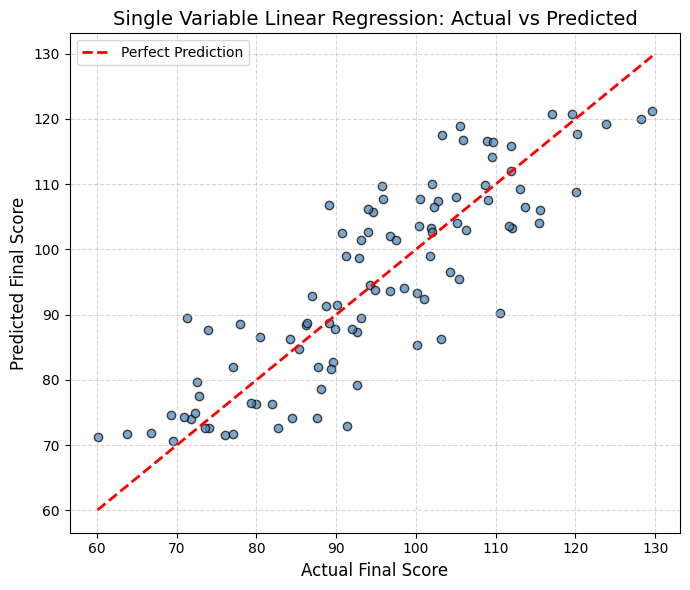

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

# Scatter plot of actual vs predicted values
plt.scatter(y_test, y_pred, color='steelblue', alpha=0.7, edgecolors='black')

# Ideal prediction line (y = x)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2,
    label='Perfect Prediction'
)

plt.xlabel("Actual Final Score", fontsize=12)
plt.ylabel("Predicted Final Score", fontsize=12)
plt.title("Single Variable Linear Regression: Actual vs Predicted", fontsize=14)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

**2. Multiple Variable Linear Regression**

In [10]:
X = df.drop('Final_Score', axis=1)
y = df['Final_Score']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [14]:
#Train the model
model = LinearRegression()
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()
model.fit(X_train_processed, y_train)

#Predict
y_pred = model.predict(X_test_processed)

In [15]:
#Evaluate
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE : 2.2872405929072523
MSE : 8.459480365348133
RMSE: 2.9085185860413776
R² Score: 0.9630013944908551


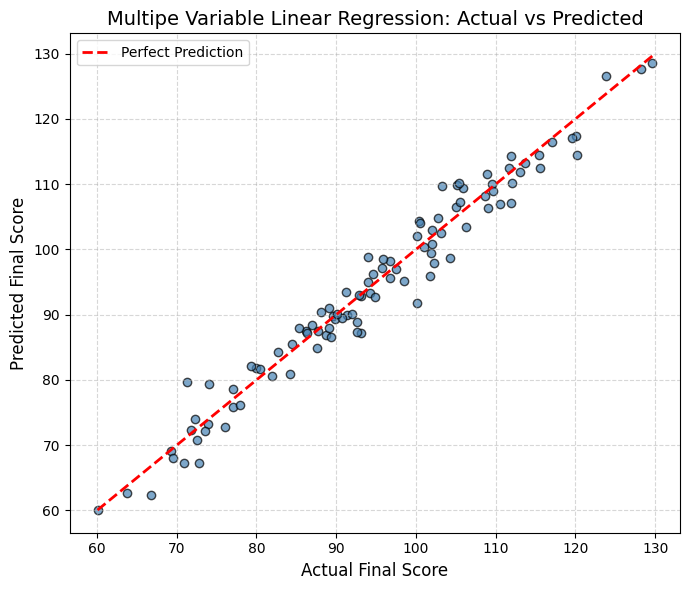

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

# Scatter plot of actual vs predicted values
plt.scatter(y_test, y_pred, color='steelblue', alpha=0.7, edgecolors='black')

# Ideal prediction line (y = x)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2,
    label='Perfect Prediction'
)

plt.xlabel("Actual Final Score", fontsize=12)
plt.ylabel("Predicted Final Score", fontsize=12)
plt.title("Multipe Variable Linear Regression: Actual vs Predicted", fontsize=14)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
v